[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hbprosper/mlinphysics/blob/main/Labs/06.GNN/tutorial_GNN.ipynb)

# Tutorial: Graph Neural Networks (GNN)
> Created Aug. 2024 for the FSU Course: *Machine Learning in Physics* <br>
> Updated: Wed Sep 24 2025: Adapted for Introduction to ML course at AIMS South Africa<br>
> Updated: Fri Jun 19 2026: Adapted for INFN SOSm Caserta, Italy<br>
> Updated: Nov 2026: Gaussian edge weights within an attention domain $\Delta R < \Delta R_\text{max}$<br>
> Harrison B. Prosper<br>


## Introduction
In this tutorial we build a **graph neural network** (GNN) similar to the one developed in the award-winning work by the IceCube Collaboration[1] which, when it was introduced, yielded state-of-the-art results in neutrino event classification.
Our goal is to classify events as **signal** or **background**, where each event is modeled as a list of data pertaining to particles: the transverse momentum of a particle, $p_T$ and its direction $(\eta, \phi)$. The quantity $\eta = -\log\tan (\theta/2)$ is the pseudo-rapidity, $\theta$ the polar angle, and $\phi$ the azimuthal angle.

In mathematics, a **graph** is a tuple $G = (V, E)$ of two sets $V = \{v_1,\cdots\}$ and $E = \{e_1,\cdots\}$ where $V$ is a set of **vertices** (or nodes) connected by **edges** that form a set $E$.
Graphs are closely related to **point clouds**, which is literally a cloud of points in some vector space. In this tutorial, each data instance, that is, event, is a point cloud $P = \{ (p_T, \eta, \phi)_i \}_{i=0}^{n-1} \in \mathbb{R}^d$, where $d = 3$ and where, in general, the number of points $n$, that is, particles, varies from one point cloud to the next. The subset of data used in this tutorial come from the website [LHC Olympics 2020](https://lhco2020.github.io/homepage/), which you should consult for a detailed description of the particle collision events.

Because the number of points varies from one point cloud to the next, we shall train the GNN with a batch size of one. PyTorch provides a flexible, sophisticated, efficient toolkit called **PyTorch Geometric** for building many different kinds of graph (see `tutorial_GNN_with_PyG`). But the purpose of this tutorial is to expose all the details of a simple specific type of GNN, namely, a **Graph Convolutional Network** (GCN).
<br clear="left"/>

## References
  1. N. Choma et al. IceCube collaboration, Graph Neural Networks for IceCube Signal Classification,  arXiv:1809.06166v1.

## Tips

  * Use __esc r__ to disable a cell
  * Use __esc y__ to reactivate it
  * Use __esc m__ to go to markdown mode. **Markdown** is the typesetting language used in jupyter notebooks.
  * In a markdown cell, double tap the mouse or glide pad (on your laptop) to go to edit mode.
  * Shift + return to execute a cell (including markdown cells).
  * If the equations don't typeset, try double tapping the cell again, and re-execute it.

## Installation of `mlinphysics`

### Local installation
  ```bash
      git clone https://github.com/hbprosper/mlinphysics
      cd mlinphysics
      pip install -e .
  ```

## Running on Google Colab
If on Google Colab (https://colab.research.google.com), execute cell below.

In [1]:
try:
    import google.colab

    REPO = 'hbprosper/mlinphysics'
    
    url = f"https://raw.githubusercontent.com/{REPO}/refs/heads/main"
    !wget -q {url}/clone2colab.ipynb -O clone2colab.ipynb
    %run clone2colab.ipynb
    
    IN_COLAB = True
    
except ImportError:
    
    IN_COLAB = False

# PART 1

In [2]:
# system modules
import os, sys

# array manipulation
import numpy as np

# Hierarchical Data Format (HDF or H5 format)
import h5py

# to reimport Python modules
import importlib

# high-quality plots
import matplotlib as mp
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

# PyTorch
import torch
import torch.nn as nn
import torch.utils.data as dt
print('torch version', torch.__version__)

# shell utilities
import shutil

# ML in physics
import drwho
import drwho.nn as mlp
import drwho.data as dat
import drwho.monitor as mon
print('drwho version', drwho.__version__)

import mlinphysics.utils.tutorials as tut

# process bar
from tqdm import tqdm

# update fonts
plt.rcParams.update({
  "text.usetex": shutil.which('latex') is not None,
  "font.family": "sans-serif",
  "font.size": 14
  })

torch version 2.14.0
drwho version 0.3.9


/Users/harry/miniconda3/envs/comphys/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Computational device

In [3]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\n\tAvailable device: {str(DEVICE):4s}\n')


	Available device: cpu 



## Load Events
The dataset comprises 36,000 events divided equally between signal and background that have been randomly shuffled. The targets can be accessed using the key 'targets' and an event is accessed by specifying the event number  'N', with the first event being '0'.

In [4]:
datafile = 'data/events.h5'

dat.download(datafile)

events, targets = tut.load_events('data/events.h5')
targets.shape, events[0].shape, events[1].shape

100%|█████████████████████████████| 36000/36000 [00:03<00:00, 9231.09it/s]



	sample size:               36000
	min[multiplicity]:            29
	avg[multiplicity] +/-std:    148.3 +/-50.1    
	max[multiplicity]:           529
	avg[pT]:                      23.4 GeV


((36000,), (107, 3), (128, 3))

## Plot Events

The particle's transverse momentum is proportional to the area of the markers.

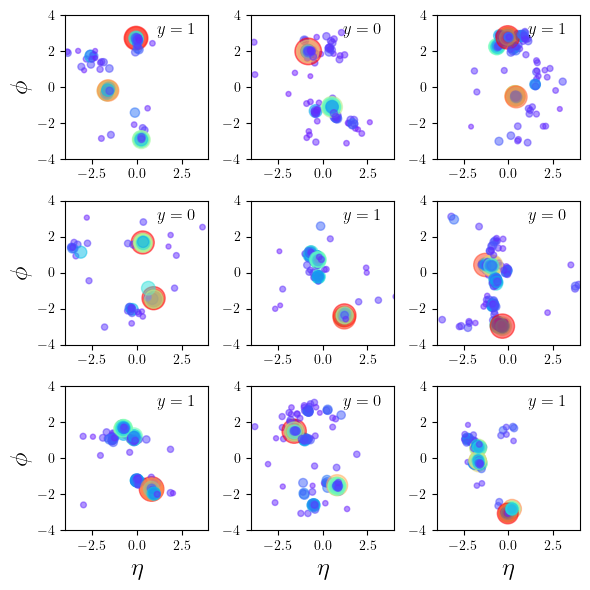

In [5]:
tut.plot_events(events, targets)

## Configuration

In [6]:
# name of model
# -----------------------------------------
name = 'sigbkg'

# create new configuration
config = mlp.Config(name, dirname='GNN')

# graph configuration
# -----------------------------------------
config('dR_max', 0.8)         # radius of the attention domain in (eta, phi):
                              # A_ij = 0 if dR_ij >= dR_max.
                              # Use None for a fully-connected graph.
config('alpha',  1.0)         # initial value of the Gaussian parameter alpha

# training configuration
# -----------------------------------------
config('train_size', 32_000)  # training sample size
config('test_size',   3_900)  # test sample size
config('val_size',      100)  # validation sample size
config('batch_size',      1)  # must be one!
config('monitor_step',  500)  # monitor training every n (=500) iterations
config('delete', True)        # delete losses file before training, if True
config('frac', 0.015)         # save model if average loss decreases by more
                              # than frac percent

# optimizer / scheduler configuration
# -----------------------------------------
# a step comprises a given number of iterations
config('n_steps', 4)                # number of training steps
config('n_iters_per_step', config('train_size'))
config('base_lr', 2.e-3)            # initial learning rate
config('gamma', 0.5)                # learning rate scale factor
configfile = config('file/config')
print(f'\nSave configuration to file {configfile}\n')

config.save()

# add number of iterations
config('n_iterations',
       config('n_iters_per_step') * \
       config('n_steps'))

print(config)


Save configuration to file runs/GNN/sigbkg_config.yaml

name: sigbkg
file:
  losses: runs/GNN/sigbkg_losses.csv
  params: runs/GNN/sigbkg_params.pth
  init_params: runs/GNN/sigbkg_init_params.pth
  plots: runs/GNN/sigbkg_plots.png
  config: runs/GNN/sigbkg_config.yaml
dR_max: 0.8
alpha: 1.0
train_size: 32000
test_size: 3900
val_size: 100
batch_size: 1
monitor_step: 500
delete: true
frac: 0.015
n_steps: 4
n_iters_per_step: 32000
base_lr: 0.002
gamma: 0.5
n_iterations: 128000



## Prepare datasets and dataloaders
  1. Scale data.
  2. Build an inhomogeneous `numpy` array of events. Why?
  3. Split data into training, testing, and validation sets.

### Create Custom Datasets

In [7]:
#                      pT, eta,   phi
scale = torch.tensor(np.array([[50.0,   5.0, np.pi]]).astype(np.float32))

sevents = [event / scale for event in events]

type(sevents), type(sevents[0]), sevents[0].device, targets.dtype

(list, torch.Tensor, device(type='cpu'), dtype('int64'))

In [8]:
importlib.reload(dat)

train_size = config('train_size')
val_size   = config('val_size')
test_size  = config('test_size')

# change type of targets from long to float (need for nn.BCELoss)
targets = torch.tensor(targets.astype(np.float32))

# training dataset (this defines the empirical risk to be minimized)
print('training data')
train_data = dat.Dataset(sevents,
                         start=0,
                         end=train_size,
                         targets=targets)

# a random subset of the training data to check for overtraining
# by comparing with the empirical risk from the validation set
print('training data for validation')
train_data_val = dat.Dataset(sevents,
                             start=0,
                             end=train_size,
                             targets=targets,
                             random_sample_size=val_size)

# validation dataset (for monitoring training)
print('validation data')
val_data = dat.Dataset(sevents,
                       start=train_size,
                       end=train_size + val_size,
                       targets=targets)

# test dataset
print('test data')
test_data= dat.Dataset(sevents,
                       start=train_size + val_size,
                       end=train_size + val_size + test_size,
                       targets=targets)

training data
Dataset
  shape of x: 32000
  shape of y: 32000

training data for validation
Dataset
  shape of x: 100
  shape of y: 100

validation data
Dataset
  shape of x: 100
  shape of y: 100

test data
Dataset
  shape of x: 3900
  shape of y: 3900



### DataLoaders

In [9]:
importlib.reload(dat)

print('train data loader')
train_loader = dat.DataLoader(
    train_data,
    batch_size=config('batch_size'),
    num_iterations=config('n_iterations'))

print('train data loader for validation')
train_loader_val = dat.DataLoader(
    train_data_val, 
    batch_size=config('batch_size'))

print('validation data loader')
val_loader = dat.DataLoader(
    val_data, 
    batch_size=config('batch_size'))

print('test data loader')
test_loader = dat.DataLoader(
    test_data, 
    batch_size=config('batch_size'))

train data loader
DataLoader
  Number of iterations has been specified
  maxiter:          128000
  batch_size:            1
  shuffle_step:      32000

train data loader for validation
DataLoader
  maxiter:             100
  batch_size:            1
  shuffle_step:        100

validation data loader
DataLoader
  maxiter:             100
  batch_size:            1
  shuffle_step:        100

test data loader
DataLoader
  maxiter:            3900
  batch_size:            1
  shuffle_step:       3900



## Build Model

### $\texttt{GaussianAdjacencyMatrix}$ `utils/tutorials.py`
This class (see `utils/tutorials.py`) computes the adjacency matrix $A$ given vertices $V$. An event with $n$ particles can be modeled as a graph with $n$ vertices. Inspired by IceCube, we model the edges of the graph as an $n \times n$ adjacency matrix $A$ with matrix elements
\begin{align}
    A_{ij} & = \frac{\exp(-\alpha \, \Delta R_{ij}^2)}{\sum_{k \in N(i)} \exp(-\alpha \, \Delta R_{ik}^2)} \quad \text{if } j \in N(i), \\
    A_{ij} & = 0 \quad \text{otherwise},
\end{align}
where $\Delta R_{ij}^2 = (\eta_i - \eta_j)^2 + (\Delta\phi_{ij})^2$ is the squared distance between particles $i$ and $j$ in $(\eta, \phi)$ space, $\Delta\phi_{ij}$ is their azimuthal difference taking into account the wraparound $\phi = +\pi \leftrightarrow \phi = -\pi$, and $N(i) = \{j : \Delta R_{ij} < \Delta R_\text{max}\}$ is the **attention domain** of particle $i$. Each row of $A$ is therefore a **softmax** of $-\alpha \Delta R_{ij}^2$, that is, a Gaussian kernel normalized to unit sum. The parameter $\alpha > 0$ is fitted; to keep it positive we fit $\log\alpha$. The distances are computed from the **unscaled** $(\eta, \phi)$: the class is told the scale factors so that it can undo the scaling of the data.

In the code, particles outside the attention domain are given the value $-\infty$ before the softmax, which the softmax turns into an exact zero. With $\Delta R_\text{max} = 0.8$, about three quarters of the elements of $A$ are zero, but we still store and multiply all $n^2$ of them! The next tutorial, `tutorial_GNN_with_PyG.ipynb`, computes exactly the same function, but stores only the non-zero elements using **PyTorch Geometric**. Following IceCube, the adjacency matrix is not changed by the graph convolution operation, but does of course change from one graph to the next.

Since the maximum number of particles is less than about 600 with a mean of about 150, it is still feasible to construct $n \times n$ matrices. For much larger $n$ one would have to use sparse matrix representations of the adjacency matrix.

Note: The $-1$ in a given tensor dimension indicates that the number of elements in that dimension is determined at runtime. In this example, that number will be the number of particles $n$.

#### A note on array broadcasting
**Broadcasting** is a powerful mechanism that makes it possible to perform many useful array or tensor manipulations. The $\texttt{GaussianAdjacencyMatrix}$ class uses broadcasting to compute all possible $\eta$ and $\phi$ differences $\Delta \eta_{ij} = \eta_i - \eta_j$ and $\Delta \phi_{ij} = \phi_i - \phi_j$ between the $n$ particles.  By changing the shapes of the tensors $\texttt{eta}$ and $\texttt{phi}$ using $\texttt{view(-1, n, 1)}$ and $\texttt{view(-1, 1, n)}$, that is, by changing their shapes to a tensor containing a single column and a tensor containing a single row, respectively, all possible $\eta$ and $\phi$ differences can be computed. (The $-1$ in the  $\texttt{dim}=0$ position of $\texttt{view}$ is the batch size, which here is 1 and determined at runtime.)

Conceptually, what happens is this. The single-column tensor constructed using $\texttt{view(-1, n, 1)}$ is  replicated to form a tensor of shape $(-1, n, n)$ in which every column is identical.  Likewise, the single-row tensor constructed using $\texttt{view(-1, 1, n)}$ is replicated to form a tensor of shape $(n, n)$ in which every row is identical. Now that the tensors are of the same shape, an elementwise subtraction is performed on the two $n \times n$ tensors, resulting in 2D tensors of shape $(n, n)$ containing all possible differences. Of course, the actual implementation is much more efficient than this!


X.shape (107, 3)
V.shape torch.Size([1, 107, 3]) tensor(1)
n = 107: 70% of the 11,449 elements are exactly zero
event torch.Size([107, 3])
graph layout kamada_kawai


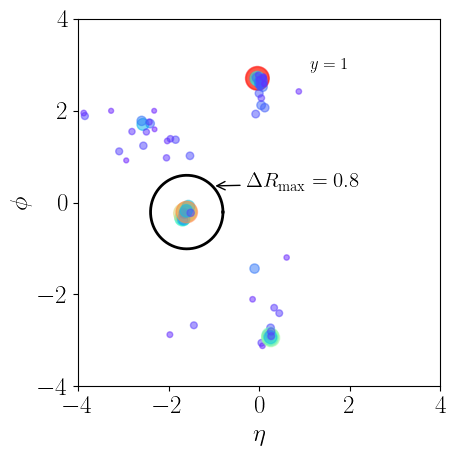

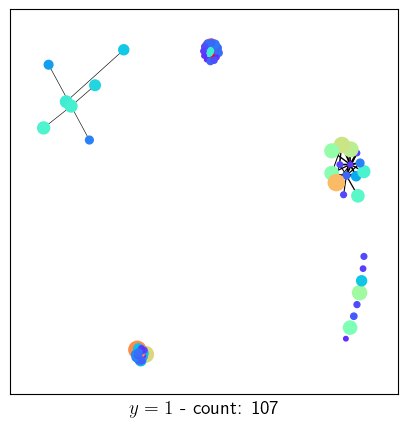

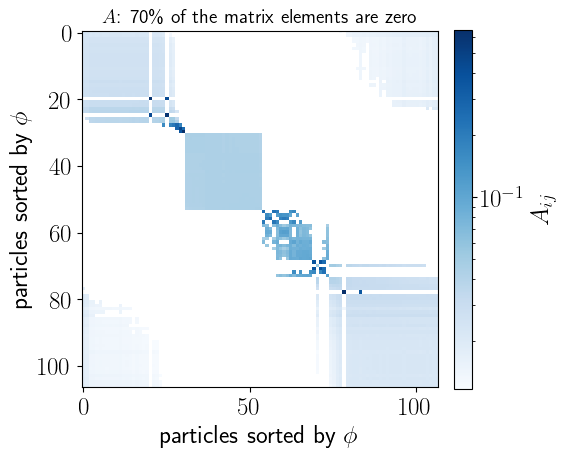

In [13]:
import importlib
importlib.reload(tut)

edges  = tut.GaussianAdjacencyMatrix(alpha=1.0, dR_max=0.8) 

# Get event
II = 0 
X = events[II].astype(np.float32)
Y = targets[II].to(torch.int64) 

V = torch.tensor(X).unsqueeze(dim=0)
print('X.shape', X.shape)
print('V.shape', V.shape, Y)

# V: tensor of shape [1, n, 3] with features (pT, eta, phi)
o  = torch.argsort(V[II, :, 2])   # order of the particles by phi
Vs = V[:, o, :] # reorder the particles, keeping each particle's features together

# compute adjacency matrix A
A  = edges(Vs).squeeze().detach().cpu().numpy().astype(np.float32)

# fraction of matrix elements that are zero
zero_fraction = (A == 0).mean()

n = len(A[0])  # number of particles
print(f'n = {n}: {100*zero_fraction:.0f}% of the {n*n:,} elements are exactly zero')

# plots
event = V.squeeze()
print('event', event.shape)
tut.plot_events([event], [Y], fgsize=(4.9, 4.9), dR_max=0.8)
tut.plot_graphs([event], [Y], scale=10)
tut.plot_adjacency_matrix(A, fgsize=(6.0, 6.0))

### Graph Convolution: $\texttt{GNNConv}$
We implement a simple graph convolutional layer from scratch, which differs from the one implemented by IceCube.
As in most GNNs, the nodes (aka vertices) are concatenated into a matrix, $X$, of shape $(n, d)$. Given a weight matrix $w$ of shape $(h, h)$, where generally $h > d$, and a matrix of ones of shape $(n, h)$ scaled by the bias parameter $b$, the graph convolution operation is defined by
\begin{align}
    X & = \sigma(X W_1^T + B_1), &\text{ embedding}\\
    X^\prime & = A X, &\text{ attention} \\
    Z & = X^\prime W_2^T + B_2 , &\text{ projection }
\end{align}
that is, a linear function that maps the nodes of $X$ to a vector in an embedding space of dimension $h$, thereby yielding a matrix of shape $(n, h)$. Then a nonlinear operation, $\sigma(*)$, is applied (usually, element wise) to every element of the embedded vectors, thereby creating new embedded vectors. This is followed by another linear function involving the adjacency matrix, $A$, which is then subject to another nonlinear operation.

For each node, the matrix operation $A X$ assigns weights to the nearest neighbors of a given vertex.  For a given node, its neighbors are the nodes within its attention domain, $\Delta R < \Delta R_\text{max}$, and the closer neighbors are weighted more than those further away. The tunable parameter $\alpha$ in the adjacency matrix $A$ determines the scale of the nearest neighbor domains. This is a simple example of an **attention** mechanism. Finally, a linear operation, which projects the updated embedded vectors to another tensor of vectors, is applied to the attention tensor $AX$.

In [15]:
class GNNConv(nn.Module):

    def __init__(self, in_features, embed_dim, out_features, 
                 activation=nn.ReLU()):

        # Initialize base class
        super().__init__()

        self.activation = activation
        
        # For embedding of the "n" input vertices in a larger 
        # vector space of dimension h = out_features
        self.embed  = nn.Linear(in_features, embed_dim)
        self.linear = nn.Linear(embed_dim, out_features)

    def forward(self, X, A):

        # Embed vertices in a larger vector space and apply
        # a non-linear function elementwise to every vector.
        X = self.embed(X) # output shape (n, h)
        X = self.activation(X)
        
        # Assign weights to the neighbors of each vertex,
        # weighting the nearest neighbors more heavily.
        # AX = A * X
        AX = torch.matmul(A, X)  # output shape (n, h)

        # Compute (A * X) * W + B, where W is of shape (h, h), and
        # B of shape (h,).
        X = self.linear(AX)
        
        # return modified vertices
        return X

### Build graph neural network (GNN)

In [16]:
class GNN(mlp.Model):

    def __init__(self, in_features, embed_dim, out_features,                  
                 activation=nn.SiLU(),
                 dropout=0.6,
                 alpha=1.0,
                 dR_max=None,
                 scale=(1.0, 1.0)):

        # initialize base class
        super().__init__()

        self.activation = activation
        
        # adjacency matrix with Gaussian weights within the attention
        # domain dR < dR_max. scale = factors by which (eta, phi) were
        # divided, so that dR can be computed in physical units.
        self.edges  = tut.GaussianAdjacencyMatrix(alpha=alpha,
                                                  dR_max=dR_max,
                                                  scale=scale)
        self.gconv1 = GNNConv(in_features, embed_dim, embed_dim)
        self.gconv2 = GNNConv(embed_dim, embed_dim, embed_dim)
        self.dropout= nn.Dropout(dropout)
        self.output = nn.Sequential(nn.Linear(embed_dim, out_features),
                                    nn.Sigmoid())

    def forward(self, V):
        #  Ok! this is a hack! Fix later!
        if type(V) == type([]):
            V = V[0]
        if V.ndim < 3:
            V = V[None, :]
            
        # V[batch_size, n=num_particles, d=num_features]
        # Construct n x n adjacency matrix which together
        # with the nodes V = x forms the graph G = (V, A)
        A = self.edges(V)
        
        # Pass graph G = (V, A) through multiple
        # graph convolution layers (graph processors)
        X = self.gconv1(V, A)
        X = self.activation(X)
        X = self.dropout(X)

        X = self.gconv2(X, A)
        X = self.activation(X)
        X = self.dropout(X)

        # Apply the simplest permutation- and vertex count-invariant
        # function to the nodes (sum embedded features over nodes)
        x = torch.mean(X, dim=1)

        # Complete with a simple MLP
        y_pred = self.output(x)
        return y_pred

## Instantiate training objects
  1. `model`
  2. `optimizer`
  1. `scheduler`
  1. `objective`
  2. `monitor`

In [17]:
model = GNN(in_features=3, embed_dim=40, out_features=1,
            alpha=config('alpha'),
            dR_max=config('dR_max'),
            scale=scale[0, 1:]).to(DEVICE)   # eta and phi scale factors
print(model)
print('number of parameters:', mlp.number_of_parameters(model))
print()

print('Parameters\n')
for name, p in model.named_parameters():
    if p.requires_grad:
        print(name)
print()

optimizer = torch.optim.Adam(model.parameters(), lr=config('base_lr'))

objective = mlp.Objective(model, nn.BCELoss()).to(DEVICE)

# instantiate learning rate step scheduler
scheduler = mlp.LRStepScheduler(
    optimizer,  
    n_steps=config('n_steps'), 
    n_iters_per_step=config('n_iters_per_step'), 
    base_lr=config('base_lr'), 
    gamma=config('gamma')
)

# instantiate object that saves average losses to
# a csv file for realtime monitoring
monitor = mon.Monitor(
    config('n_iterations'),
    config('file/losses'),
    monitorstep=config('monitor_step'),
    newlossfile=True,
    frac=config('frac'),
    model=model,
    paramsfile=config('file/params'), 
    use_tensorboard=False)

GNN(
  (activation): SiLU()
  (edges): GaussianAdjacencyMatrix()
  (gconv1): GNNConv(
    (activation): ReLU()
    (embed): Linear(in_features=3, out_features=40, bias=True)
    (linear): Linear(in_features=40, out_features=40, bias=True)
  )
  (gconv2): GNNConv(
    (activation): ReLU()
    (embed): Linear(in_features=40, out_features=40, bias=True)
    (linear): Linear(in_features=40, out_features=40, bias=True)
  )
  (dropout): Dropout(p=0.6, inplace=False)
  (output): Sequential(
    (0): Linear(in_features=40, out_features=1, bias=True)
    (1): Sigmoid()
  )
)
number of parameters: 5122

Parameters

edges.log_alpha
gconv1.embed.weight
gconv1.embed.bias
gconv1.linear.weight
gconv1.linear.bias
gconv2.embed.weight
gconv2.embed.bias
gconv2.linear.weight
gconv2.linear.bias
output.0.weight
output.0.bias

number of milestones:          3

Step | Milestone | LR
-----------------------------
   0 |         0 | 2.0e-03   
-----------------------------
   1 |     32000 | 1.0e-03   
   2 |  

## Define trainer

In [18]:
importlib.reload(mlp)

def train(objective, optimizer, scheduler, monitor,
          train_loader, train_small_loader, val_loader):

    # This is miserably slow, so use it sparingly
    def Im_a_sloth(loader):
        losses = [objective(x, y[None,:]) for x, y in loader]
        return torch.stack(losses).mean().item()
        
    monitor.start()

    for x, y in train_loader:
        
        # set mode to training so that training-specific
        # operations such as dropout, etc., are enabled.
        objective.train()

        # clear all gradients
        optimizer.zero_grad()

        R = objective(x, y[None, :])

        # compute gradients
        R.backward()

        # take one step downhill in the empirical risk landscape
        optimizer.step()

        # check whether to update learning rate
        scheduler.step()

        if monitor.step():

            # compute average losses on training and validation data
            with torch.no_grad():
                
                # set mode to evaluation so that training-specific
                # operations such as dropout, etc., are disabled.
                objective.eval()

                t_loss = Im_a_sloth(train_loader_val)

                v_loss = Im_a_sloth(val_loader)
           
            # return current learning rate
            lr = scheduler.lr()

            # update loss file
            monitor(t_loss, v_loss, lr)
                
    monitor.terminate(5)

## Train Model

In [19]:
#%pip install line_profiler
#%load_ext line_profiler

In [20]:
TRAIN = True

if TRAIN:
      
    #%lprun -f train -f monitor.__call__ 
    train(
        objective, optimizer, scheduler, monitor,
        train_loader, train_loader_val, val_loader)

monlosses runs/GNN/sigbkg_losses.csv

		learning rate:  2.000e-03
     31500| 24.61%|00:00:37|00:01:54| 844.7 it/s|4.329e-01|3.944e-01|     31500|
		learning rate:  1.000e-03
     63500| 49.61%|00:01:13|00:01:15| 859.5 it/s|4.842e-01|3.452e-01|     63500|
		learning rate:  5.000e-04
     95500| 74.61%|00:01:51|00:00:37| 859.7 it/s|4.295e-01|3.183e-01|     95500|
		learning rate:  2.500e-04
    127500| 99.61%|00:02:28|00:00:00| 858.4 it/s|4.787e-01|3.476e-01|    127500|
	Terminating standalone loss monitor...
	Done!


## Plot Results

  1. Confusion matrix for signals defined by $y \geq 1/2$.
  2. Classifier distribution $\hat{y} = D(G)$.
  3. ROC curve

**NB**: In the following codes, the first argument is always the targets $y$ and the second the model predictions $\hat{y}$.

fitted alpha: 5.87e-06


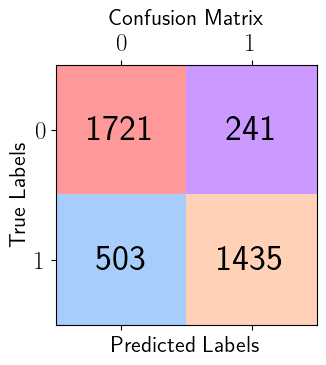

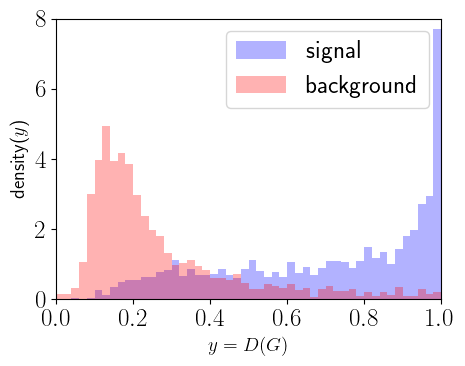

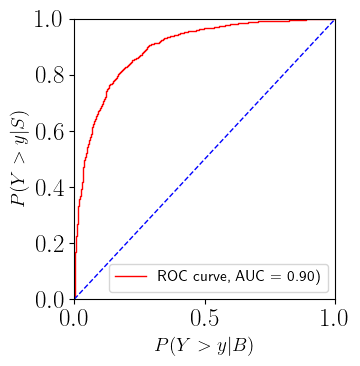

In [21]:
importlib.reload(tut)

# load the best model and set it to evaluation mode (no dropout)
model.load(config('file/params'))
model.eval()

print(f'fitted alpha: {model.edges.alpha().item():.2e}')

with torch.no_grad():
    Y = np.array([(float(model(x).cpu()),
                   float(y.cpu())) for x, y in test_loader])
y_hat, test_targets = Y.T
test_preds = (y_hat > 0.5).astype(int)

tut.plot_confusion_matrix(test_targets, test_preds)
tut.histogram_classifier_outputs(test_targets, y_hat)
tut.plot_roc(test_targets, y_hat)